# Milestone 3: Measuring compression and image quality

How much storage do we save, and how much detail do we lose? We compare the numbers with the images before choosing a rank for the bird photo.

In [1]:
from pathlib import Path
import subprocess
import sys

# Use this checkout locally, or download the project when running in Colab.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "bird_image.jpg").exists() and (p / "src").is_dir()), None)
if ROOT is None:
    ROOT = Path.cwd() / "LinAlgProject"
    if (ROOT / ".git").exists():
        subprocess.run(["git", "-C", str(ROOT), "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", "https://github.com/matbarrett/LinAlgProject.git",
                        str(ROOT)], check=True)
sys.path.insert(0, str(ROOT / "src"))
print("Project:", ROOT.name)

Project: LinAlgProject


This loads the functions from `src/compress.py`. In Colab, it downloads the repo if it is not already there.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from compress import rank_k_approx, storage, compression_ratio, rel_error, predicted_error

from skimage import data
A = data.camera().astype(float)
T = data.text().astype(float)
img = Image.open(ROOT / "bird_image.jpg").convert("L")
img.thumbnail((800, 800))
P = np.array(img)
P_float = P.astype(float)
print("Camera:", A.shape, "Text:", T.shape, "Bird:", P.shape)
figures = ROOT / "figures"
figures.mkdir(exist_ok=True)

Camera: (512, 512) Text: (172, 448) Bird: (678, 452)


The camera, text, and bird images are loaded here and converted to float for the calculations. This notebook can run without running Milestone 1 first.

## B. How many numbers are stored?

In [3]:
m, n = A.shape
print("Original camera values:", m * n)
for k in [1, 10, 50, 100, 255, 256]:
    print(f"k={k:3d} stored={storage(m, n, k):6d} ratio={compression_ratio(m, n, k):.3f}")

Original camera values: 262144
k=  1 stored=  1025 ratio=255.750
k= 10 stored= 10250 ratio=25.575
k= 50 stored= 51250 ratio=5.115
k=100 stored=102500 ratio=2.558
k=255 stored=261375 ratio=1.003
k=256 stored=262400 ratio=0.999


The factors store `k*m` entries in U, k singular values, and `k*n` entries in Vt: `k*(m+n+1)` altogether. A ratio above 1 means fewer numbers to store. For camera, k = 255 just barely saves values; k = 256 uses more than the original.

## C. Reconstruction error

In [4]:
for k in [1, 5, 20, 50, 100]:
    Ak = rank_k_approx(A, k)
    print(f"k={k:3d} relative error={rel_error(A, Ak):.4f}")

k=  1 relative error=0.3604


k=  5 relative error=0.1720


k= 20 relative error=0.1012


k= 50 relative error=0.0636


k=100 relative error=0.0393


Relative error divides the Frobenius norm of the difference by the norm of the original image. For camera, it drops from about 36% at k = 1 to about 4% at k = 100.

## D. Predicting error

In [5]:
U, s, Vt = np.linalg.svd(A, full_matrices=False)
for k in [1, 5, 20, 50, 100]:
    actual = rel_error(A, rank_k_approx(A, k))
    predicted = predicted_error(s, k)
    print(f"k={k:3d} actual={actual:.6f} predicted={predicted:.6f}")
    assert np.isclose(actual, predicted)

k=  1 actual=0.360449 predicted=0.360449
k=  5 actual=0.172014 predicted=0.172014


k= 20 actual=0.101208 predicted=0.101208
k= 50 actual=0.063565 predicted=0.063565


k=100 actual=0.039329 predicted=0.039329


The measured and predicted errors match at every rank checked. The prediction uses `s[k:]`, the singular values we left out, so we do not have to rebuild the image for every point on the error curve.

## E. Smallest rank for a target error

In [6]:
ranks = np.arange(1, len(s) + 1)
errors = np.array([predicted_error(s, int(k)) for k in ranks])
for target in [0.10, 0.05, 0.02, 0.01]:
    k = int(ranks[errors <= target][0])
    print(f"Target={target:.0%}: k={k}, error={predicted_error(s, k):.4f}, ratio={compression_ratio(m, n, k):.2f}")

Target=10%: k=21, error=0.0988, ratio=12.18
Target=5%: k=73, error=0.0496, ratio=3.50
Target=2%: k=186, error=0.0198, ratio=1.38
Target=1%: k=263, error=0.0100, ratio=0.97


Camera needs k = 21 to get below 10% error, but k = 263 to get below 1%. At k = 263, the ratio is only 0.97, so reaching that last target takes more factor entries than the original has pixels.

## F. Camera versus text

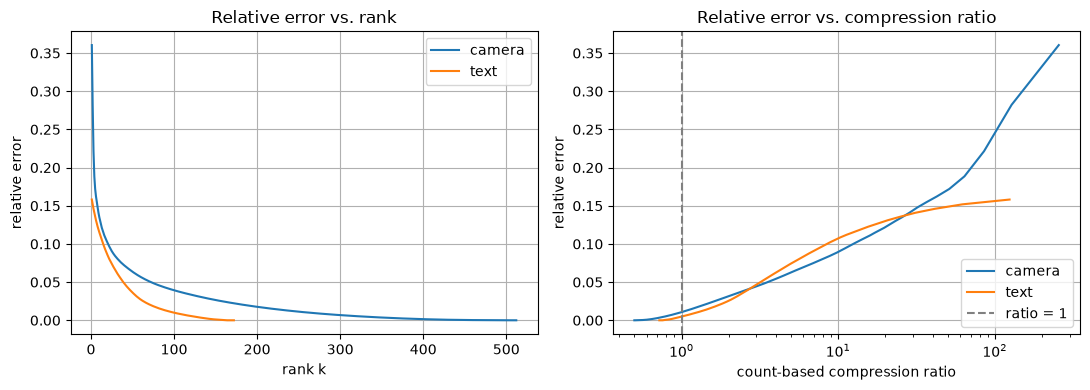

In [7]:
images = {"camera": A, "text": T}
spectra = {name: np.linalg.svd(M, compute_uv=False) for name, M in images.items()}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for name, M in images.items():
    mi, ni = M.shape
    si = spectra[name]
    rr = np.arange(1, len(si) + 1)
    ee = [predicted_error(si, int(k)) for k in rr]
    ratios = [compression_ratio(mi, ni, int(k)) for k in rr]
    ax1.plot(rr, ee, label=name)
    ax2.semilogx(ratios, ee, label=name)
ax1.set(title="Relative error vs. rank", xlabel="rank k", ylabel="relative error")
ax2.axvline(1, color="gray", linestyle="--", label="ratio = 1")
ax2.set(title="Relative error vs. compression ratio", xlabel="count-based compression ratio", ylabel="relative error")
for ax in (ax1, ax2):
    ax.grid()
    ax.legend()
plt.tight_layout()
plt.savefig(figures / "error_vs_ratio.png", dpi=150)
plt.show()

Text has less relative error at the same rank, but the comparison changes when we account for storage. The images have different dimensions, so each SVD term costs a different number of entries. The dashed line marks a ratio of 1, where there is no saving.

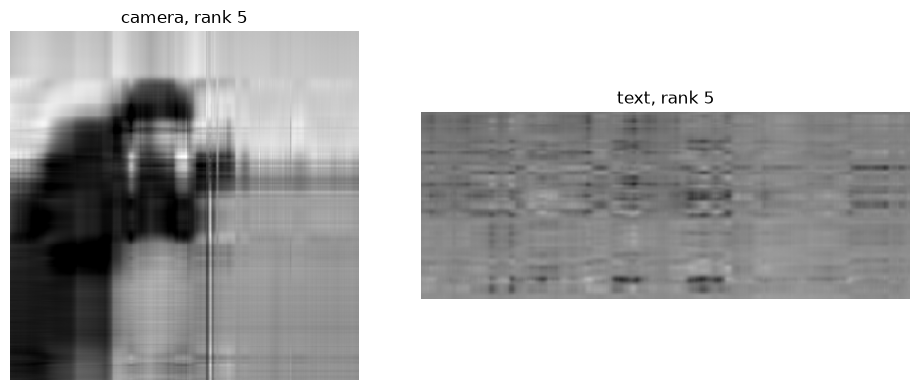

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, M) in zip(axes, images.items()):
    ax.imshow(np.clip(rank_k_approx(M, 5), 0, 255), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{name}, rank 5")
    ax.axis("off")
plt.tight_layout()
plt.show()

At rank 5, the broad shapes are still there, but the letters are hard to read. That is why we need to look at the result as well as its error.

## G. Clipping pixels

In [9]:
A20 = rank_k_approx(A, 20)
outside = (A20 < 0) | (A20 > 255)
print("Out-of-range pixels:", outside.sum())
print("Fraction:", f"{outside.mean():.1%}")
print("Error before clipping:", rel_error(A, A20))
print("Error after clipping:", rel_error(A, np.clip(A20, 0, 255)))

Out-of-range pixels: 2634
Fraction: 1.0%
Error before clipping: 0.1012077568277273
Error after clipping: 0.10083571385013856


About 1% of the camera pixels fall outside 0 to 255 at rank 20. Clipping lowers the relative error slightly, from about 0.1012 to 0.1008. It moves those values closer to the originals. The singular-value prediction describes the result before clipping; clipping can change its rank.

## H. Project photograph

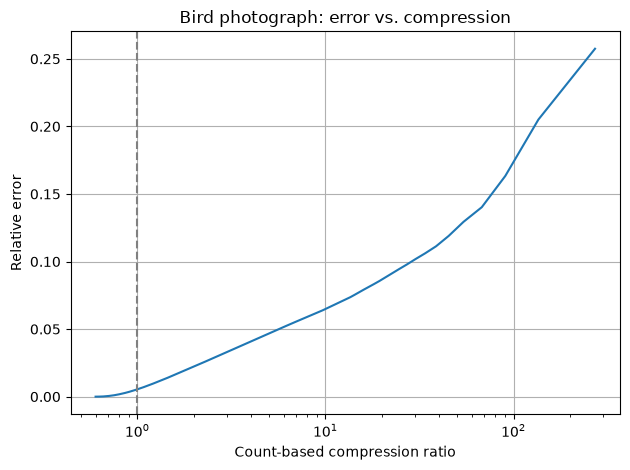

In [10]:
sp = np.linalg.svd(P_float, compute_uv=False)
kp = np.arange(1, len(sp) + 1)
ep = np.array([predicted_error(sp, int(k)) for k in kp])
mp, npix = P_float.shape
rp = [compression_ratio(mp, npix, int(k)) for k in kp]
plt.semilogx(rp, ep)
plt.axvline(1, color="gray", linestyle="--")
plt.xlabel("Count-based compression ratio")
plt.ylabel("Relative error")
plt.title("Bird photograph: error vs. compression")
plt.grid()
plt.tight_layout()
plt.savefig(figures / "bird_error_vs_ratio.png", dpi=150)
plt.show()

Keeping fewer terms moves us toward a larger compression ratio and a larger error. Exercise 6 checks what one point on this curve actually looks like.

## Practice exercises

### 1. When does compression stop saving values?
We need `k*(m+n+1) < m*n`, so `k < m*n/(m+n+1)`. The largest integer is `ceil(m*n/(m+n+1)) - 1`. The strict inequality matters when the quotient is an integer. Since these are positive integers, `(m*n - 1) // (m+n+1)` gives the same answer.

For bytes, a uint8 pixel takes one byte and each float64 factor entry takes eight. The inequality becomes `8*k*(m+n+1) < m*n`, with largest k equal to `(m*n - 1) // (8*(m+n+1))`.

In [11]:
print("Factor dtype:", U.dtype, "bytes per entry:", U.itemsize)
for name, M in images.items():
    mi, ni = M.shape
    value_limit = (mi * ni - 1) // (mi + ni + 1)
    byte_limit = (mi * ni - 1) // (U.itemsize * (mi + ni + 1))
    print(f"{name}: max saving rank by values={value_limit}, by bytes={byte_limit}")
    print(f"  stops saving values at k={value_limit + 1}; bytes at k={byte_limit + 1}")
    assert storage(mi, ni, value_limit) < mi * ni <= storage(mi, ni, value_limit + 1)

Factor dtype: float64 bytes per entry: 8
camera: max saving rank by values=255, by bytes=31
  stops saving values at k=256; bytes at k=32
text: max saving rank by values=124, by bytes=15
  stops saving values at k=125; bytes at k=16


Camera stops saving values at k = 256, but stops saving bytes at k = 32. For text, those cutoffs are 125 and 16. The difference comes from storing each factor entry in 8 bytes instead of 1. This compares raw arrays, so it does not tell us how the factors compare with a JPEG file.

### 2. Why does predicted error work?

In [12]:
print("Squared Frobenius norm:", np.linalg.norm(A)**2)
print("Sum of squared singular values:", np.sum(s**2))
print("Agree?", np.isclose(np.linalg.norm(A)**2, np.sum(s**2)))

Squared Frobenius norm: 5788200983.000001
Sum of squared singular values: 5788200982.999999
Agree? True


Orthogonal SVD factors preserve the Frobenius norm, so the total squared image norm is the sum of all squared singular values. Eckart-Young says the squared rank-k error is the sum of the discarded squared values. Dividing those sums and taking the square root gives relative error.

### 3. Numbers versus readability

Most populated brightness bin: 140.9 to 144.6


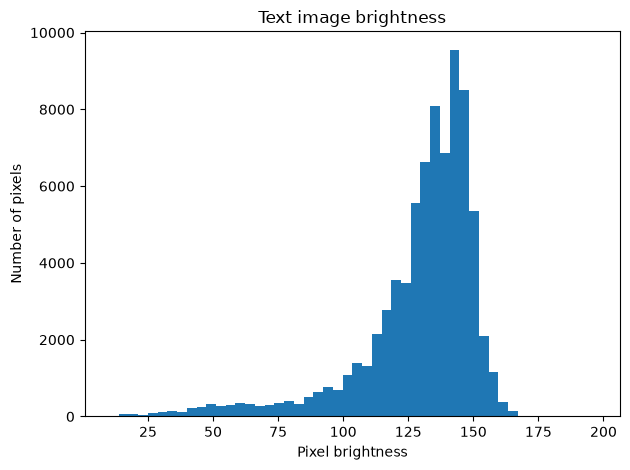

In [13]:
counts, bins, _ = plt.hist(T.ravel(), bins=50)
peak = int(np.argmax(counts))
print(f"Most populated brightness bin: {bins[peak]:.1f} to {bins[peak + 1]:.1f}")
plt.xlabel("Pixel brightness")
plt.ylabel("Number of pixels")
plt.title("Text image brightness")
plt.tight_layout()
plt.savefig(figures / "text_histogram.png", dpi=150)
plt.show()

Most pixels are around 120 to 155, with the tallest bin around 141 to 145. The gray background takes up much more space than the dark letters. An approximation can get that background mostly right and still blur the words. Another useful check would be to read the same line in each approximation and count the words that are still readable.

### 4. Compare the project image at 10% error

In [14]:
all_images = {**images, "bird": P_float}
all_spectra = {**spectra, "bird": sp}
results = {}
for name, M in all_images.items():
    si = all_spectra[name]
    k = next(k for k in range(1, len(si) + 1) if predicted_error(si, k) <= 0.10)
    ratio = compression_ratio(*M.shape, k)
    results[name] = ratio
    print(f"{name}: k={k}, error={predicted_error(si, k):.4f}, ratio={ratio:.2f}")
print("Largest ratio at 10% error:", max(results, key=results.get))

camera: k=21, error=0.0988, ratio=12.18
text: k=15, error=0.0989, ratio=8.27
bird: k=10, error=0.0979, ratio=27.10
Largest ratio at 10% error: bird


The bird photo has the largest compression ratio at 10% error: 27.10 at k = 10. Camera reaches 12.18 at k = 21, and text reaches 8.27 at k = 15. For the bird, the first ten singular values account for enough of the total squared values to meet the target. Its large subject and plain background help explain why relatively few terms work. The image dimensions also affect the storage ratio.

### 5. Why clipping cannot increase error
Let the original pixel be a in [0, 255].

- If x < 0, clipping gives 0. Then `|0-a| = a <= a-x = |x-a|`.
- If 0 <= x <= 255, clipping leaves x unchanged.
- If x > 255, clipping gives 255. Then `|255-a| = 255-a <= x-a = |x-a|`.

So no pixel gets farther from its true value. Squaring the errors, summing them, and taking a square root preserves this inequality. Therefore clipping cannot increase the Frobenius error either.

### 6. Choosing a rank

Chosen rank: 20
Relative error (before clipping): 0.07361226348171425
Count-based compression ratio: 13.548010610079576
uint8 original / float64 factors byte ratio: 1.693501326259947


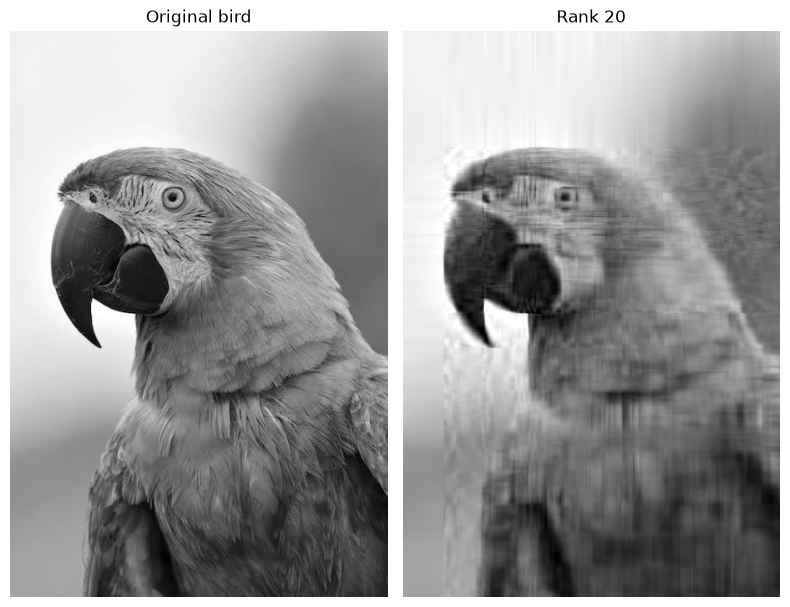

In [15]:
chosen_k = 20
chosen = rank_k_approx(P_float, chosen_k)
value_ratio = compression_ratio(mp, npix, chosen_k)
byte_ratio = value_ratio / np.dtype(float).itemsize
print("Chosen rank:", chosen_k)
print("Relative error (before clipping):", rel_error(P_float, chosen))
print("Count-based compression ratio:", value_ratio)
print("uint8 original / float64 factors byte ratio:", byte_ratio)
fig, axes = plt.subplots(1, 2, figsize=(8, 7))
for ax, image, title in zip(axes, [P_float, np.clip(chosen, 0, 255)], ["Original bird", f"Rank {chosen_k}"]):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig(figures / "bird_chosen_rank.png", dpi=150, bbox_inches="tight")
plt.show()

We would choose k = 20 for a small preview. The relative error is 7.36%, and the ratio is 13.55 when counting values. With float64 factors and uint8 pixels, the byte ratio is 1.69, saving about 41% of the raw storage. The beak, eye, and head shape are visible next to the original, but the feathers are blurred and there are streaks in the image. That seems acceptable for a preview; a larger rank would be better for showing the feather detail. This is a saving over raw pixels, not over the JPEG file.